In [ ]:
# M&A Deal Dynamics & Regulatory Scrutiny Analyzer

# A Python research project using Bloomberg M&A transaction data (2015–2024)

# Research question: Are M&A transactions with recorded regulatory involvement associated with longer deal timelines or different completion outcomes?

# This project uses Python to examine approximately 5,000 M&A transactions from 2015 through 2024. It investigates the relationship between recorded antitrust or foreign-investment regulatory dates, transaction duration, and deal completion outcomes.

# The analysis combines exploratory data analysis, statistical hypothesis testing, and multivariable regression to examine these relationships while accounting for observable deal characteristics.



In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import fisher_exact
import statsmodels.formula.api as smf
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")

DATA_FILE = '/Users/nathanieldarocha/Downloads/M&A_deals_2015-2024.xlsx'
data_path = Path(DATA_FILE)

if not data_path.exists():
    # Google Colab upload option
    try:
        from google.colab import files
        uploaded = files.upload()
        data_path = Path(next(iter(uploaded)))
    except ImportError:
        # Local Jupyter file picker
        try:
            import tkinter as tk
            from tkinter import filedialog
            root = tk.Tk()
            root.withdraw()
            selected_file = filedialog.askopenfilename(
                title="Select your Bloomberg M&A Excel file",
                filetypes=[("Excel files", "*.xlsx *.xls")]
            )
            root.destroy()
            if selected_file:
                data_path = Path(selected_file)
            else:
                raise FileNotFoundError("No file selected. Set DATA_FILE to your Excel file path.")
        except Exception as error:
            raise FileNotFoundError(
                "Could not open a file picker. Set DATA_FILE to the full path of your Excel file."
            ) from error

df = pd.read_excel(data_path)
print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()

Dataset loaded successfully.
Rows: 5,000 | Columns: 13


,Deal Type,Announce Date,Target Name,Target Ticker,Acquirer Name,Seller Name,Announced Total Value (mil.),Payment Type,Deal Status,Completion/Termination Date,Anti-Trust Commission,FIC: Foreign Investment Committee,Action ID
0,M&A,2015-11-23,Pfizer Inc,PFE US,Allergan Ltd/Ireland,NaN,183068.25,Stock,Terminated,2016-04-06 00:00:00,NaT,NaT,116076732
1,M&A,2017-03-10,BP PLC,BP/ LN,ExxonMobil Holdings Corp,NaN,181516.34,Undisclosed,Withdrawn,2017-09-21 00:00:00,NaT,NaT,141836825
2,M&A,2017-01-26,Charter Communications Inc,CHTR US,Verizon Communications Inc,NaN,169097.16,Cash,Withdrawn,2017-12-01 00:00:00,NaT,NaT,139271080
3,M&A,2017-02-17,Unilever PLC,ULVR LN,Kraft Heinz Co/The,NaN,163350.91,Cash and Stock,Withdrawn,2017-02-19 00:00:00,NaT,NaT,140568450
4,M&A,2020-09-29,Duke Energy Corp,DUK US,NextEra Energy Inc,NaN,132295.09,Undisclosed,Withdrawn,2020-10-05 00:00:00,NaT,NaT,222107931


In [2]:
print(df.shape)
print(df.columns.tolist())

(5000, 13)
['Deal Type', 'Announce Date', 'Target Name', 'Target Ticker', 'Acquirer Name', 'Seller Name', 'Announced Total Value (mil.)', 'Payment Type', 'Deal Status', 'Completion/Termination Date', 'Anti-Trust Commission', 'FIC: Foreign Investment Committee', 'Action ID']


In [3]:
print("COLUMN NAMES")
print(df.columns.tolist())

print("\nDATA TYPES AND NON-MISSING COUNTS")
df.info()

print("\nMISSING VALUES")
missing_summary = (
    df.isna().sum()
      .rename("missing_count")
      .to_frame()
)
missing_summary["missing_percent"] = (
    missing_summary["missing_count"] / len(df) * 100
).round(2)
display(missing_summary.sort_values("missing_percent", ascending=False))

print("\nDEAL STATUS COUNTS")
display(df["Deal Status"].value_counts(dropna=False).to_frame("transactions"))

COLUMN NAMES
['Deal Type', 'Announce Date', 'Target Name', 'Target Ticker', 'Acquirer Name', 'Seller Name', 'Announced Total Value (mil.)', 'Payment Type', 'Deal Status', 'Completion/Termination Date', 'Anti-Trust Commission', 'FIC: Foreign Investment Committee', 'Action ID']

DATA TYPES AND NON-MISSING COUNTS
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Deal Type                          5000 non-null   str           
 1   Announce Date                      5000 non-null   datetime64[us]
 2   Target Name                        5000 non-null   str           
 3   Target Ticker                      4978 non-null   str           
 4   Acquirer Name                      5000 non-null   str           
 5   Seller Name                        233 non-null    str           
 6   Announced Total Val

,missing_count,missing_percent
FIC: Foreign Investment Committee,4998,99.96
Anti-Trust Commission,4870,97.40
Seller Name,4767,95.34
Announced Total Value (mil.),885,17.70
Target Ticker,22,0.44
Deal Type,0,0.00
Announce Date,0,0.00
Target Name,0,0.00
Acquirer Name,0,0.00
Payment Type,0,0.00



DEAL STATUS COUNTS


,transactions
Deal Status,
Completed,3328
Withdrawn,1133
Terminated,312
Pending,227


In [4]:
# Working on a copy so the original imported data remains unchanged.
deals = df.copy()

# Convert date fields to datetime.
date_columns = [
    "Announce Date",
    "Completion/Termination Date",
    "Anti-Trust Commission",
    "FIC: Foreign Investment Committee"
]

for column in date_columns:
    deals[column] = pd.to_datetime(deals[column], errors="coerce")

# Identify transactions with recorded regulatory dates.
deals["regulatory_recorded"] = (
    deals["Anti-Trust Commission"].notna()
    | deals["FIC: Foreign Investment Committee"].notna()
).astype(int)

# Calculate announcement-to-completion/termination duration.
deals["deal_duration_days"] = (
    deals["Completion/Termination Date"] - deals["Announce Date"]
).dt.days

# Extract announcement year.
deals["announcement_year"] = deals["Announce Date"].dt.year

# Convert announced deal value to numeric.
deals["deal_value_millions"] = pd.to_numeric(
    deals["Announced Total Value (mil.)"], errors="coerce"
)

# Check duplicate Action IDs before making any changes.
duplicate_action_ids = deals["Action ID"].duplicated(keep=False).sum()

print(f"Rows with duplicate Action IDs: {duplicate_action_ids:,}")
print(f"Unique Action IDs: {deals['Action ID'].nunique():,}")
print(f"Transactions with recorded regulatory dates: {deals['regulatory_recorded'].sum():,}")
print(f"Pending transactions: {(deals['Deal Status'] == 'Pending').sum():,}")
print(f"Missing deal durations: {deals['deal_duration_days'].isna().sum():,}")
print(f"Negative deal durations: {(deals['deal_duration_days'] < 0).sum():,}")

Rows with duplicate Action IDs: 0
Unique Action IDs: 5,000
Transactions with recorded regulatory dates: 132
Pending transactions: 227
Missing deal durations: 151
Negative deal durations: 19


In [5]:
quality_checks = pd.DataFrame({
    "Check": [
        "Total transactions",
        "Missing announcement dates",
        "Missing completion/termination dates",
        "Missing deal durations",
        "Negative deal durations",
        "Zero-day deal durations",
        "Missing announced deal values",
        "Transactions with regulatory date recorded",
        "Pending transactions"
    ],
    "Count": [
        len(deals),
        deals["Announce Date"].isna().sum(),
        deals["Completion/Termination Date"].isna().sum(),
        deals["deal_duration_days"].isna().sum(),
        (deals["deal_duration_days"] < 0).sum(),
        (deals["deal_duration_days"] == 0).sum(),
        deals["deal_value_millions"].isna().sum(),
        deals["regulatory_recorded"].sum(),
        deals["Deal Status"].eq("Pending").sum()
    ]
})

quality_checks["Percent of Transactions"] = (
    quality_checks["Count"] / len(deals) * 100
).round(2)

display(quality_checks)

,Check,Count,Percent of Transactions
0,Total transactions,5000,100.00
1,Missing announcement dates,0,0.00
2,Missing completion/termination dates,151,3.02
3,Missing deal durations,151,3.02
4,Negative deal durations,19,0.38
5,Zero-day deal durations,246,4.92
6,Missing announced deal values,885,17.70
7,Transactions with regulatory date recorded,132,2.64
8,Pending transactions,227,4.54


In [6]:
# Identify non-pending transactions with missing durations.
missing_non_pending = deals[
    deals["deal_duration_days"].isna()
    & deals["Deal Status"].ne("Pending")
]

print("NON-PENDING TRANSACTIONS WITH MISSING DURATIONS")
print(f"Count: {len(missing_non_pending)}")

display(missing_non_pending[[
    "Target Name",
    "Acquirer Name",
    "Deal Status",
    "Announce Date",
    "Completion/Termination Date"
]])

# Inspect transactions with negative durations.
negative_duration_deals = deals[
    deals["deal_duration_days"] < 0
]

print("\nNEGATIVE-DURATION TRANSACTIONS")
print(f"Count: {len(negative_duration_deals)}")

display(negative_duration_deals[[
    "Target Name",
    "Acquirer Name",
    "Deal Status",
    "Announce Date",
    "Completion/Termination Date",
    "deal_duration_days"
]])

NON-PENDING TRANSACTIONS WITH MISSING DURATIONS
Count: 0


,Target Name,Acquirer Name,Deal Status,Announce Date,Completion/Termination Date



NEGATIVE-DURATION TRANSACTIONS
Count: 19


,Target Name,Acquirer Name,Deal Status,Announce Date,Completion/Termination Date,deal_duration_days
1800,Arsenal Holdings Ltd,KSE UK Inc,Completed,2018-08-07,2018-05-31,-68.0
2677,JAKKS Pacific Inc,Potential Buyer,Withdrawn,2019-09-05,2019-03-05,-184.0
3098,Brigham Minerals Inc,Potential Buyer,Withdrawn,2022-08-03,2022-05-03,-92.0
3108,Evolent Health Inc,Walgreens Boots Alliance Inc,Withdrawn,2021-09-29,2021-03-29,-184.0
3614,Royal Orchid Hotel Thailand PCL,Grande Asset Hotels & Property PCL,Completed,2018-05-03,2018-04-25,-8.0
3906,True North Consulting LLC,GSE Systems Inc,Completed,2018-05-14,2018-05-11,-3.0
4010,Ecotec Co Ltd/Korea,"Private Investor,Axios Equity Fund LLC",Pending,2024-09-10,2024-09-09,-1.0
4075,Micromobility.com Inc,Palella Holdings LLC,Completed,2024-06-11,2024-06-10,-1.0
4086,Credex Corp,Cannabis Depot Holding Corp/The,Completed,2021-06-24,2021-06-17,-7.0
4088,Universal Global Hub Inc,Eastone Equities LLC,Completed,2017-10-13,2017-10-09,-4.0


In [7]:
# Create a separate dataset for duration-based analysis.
# Keep the original deals dataset intact.

duration_deals = deals[
    deals["deal_duration_days"].notna()
    & (deals["deal_duration_days"] >= 0)
    & deals["Deal Status"].ne("Pending")
].copy()

print("DURATION ANALYSIS SAMPLE")
print(f"Transactions included: {len(duration_deals):,}")
print(f"Transactions excluded: {len(deals) - len(duration_deals):,}")
print(f"Negative durations excluded: {(deals['deal_duration_days'] < 0).sum():,}")
print(f"Pending transactions excluded: {deals['Deal Status'].eq('Pending').sum():,}")
print(f"Median deal duration: {duration_deals['deal_duration_days'].median():.1f} days")
print(f"Mean deal duration: {duration_deals['deal_duration_days'].mean():.1f} days")

DURATION ANALYSIS SAMPLE
Transactions included: 4,755
Transactions excluded: 245
Negative durations excluded: 19
Pending transactions excluded: 227
Median deal duration: 128.0 days
Mean deal duration: 149.9 days


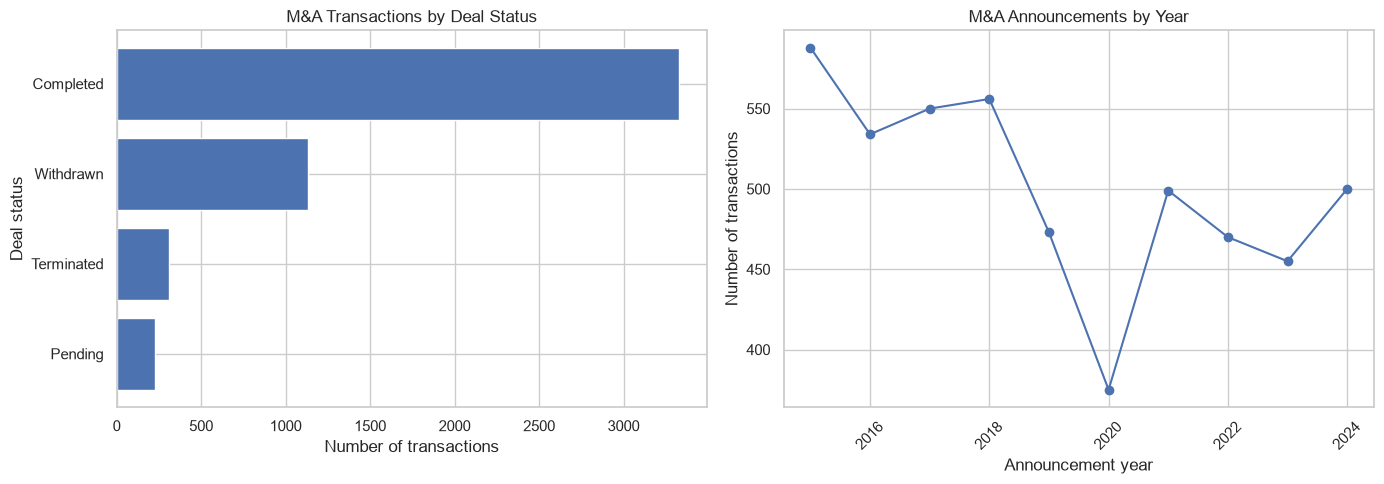

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

status_counts = deals["Deal Status"].value_counts()
axes[0].barh(status_counts.index[::-1], status_counts.values[::-1])
axes[0].set_title("M&A Transactions by Deal Status")
axes[0].set_xlabel("Number of transactions")
axes[0].set_ylabel("Deal status")

year_counts = deals.groupby("announcement_year").size()
axes[1].plot(year_counts.index, year_counts.values, marker="o")
axes[1].set_title("M&A Announcements by Year")
axes[1].set_xlabel("Announcement year")
axes[1].set_ylabel("Number of transactions")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

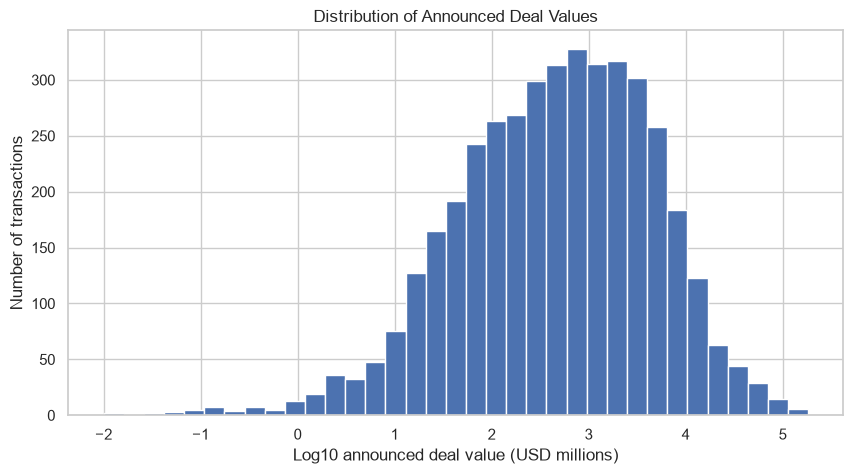

Deal value summary (USD millions)


,deal_value_millions
count,4112.000000
mean,3337.454290
std,10453.260558
min,0.010000
25%,96.157500
50%,526.985000
75%,2460.607500
max,183068.250000


In [9]:
valid_values = deals.loc[deals["deal_value_millions"] > 0, "deal_value_millions"].dropna()

plt.figure(figsize=(10, 5))
plt.hist(np.log10(valid_values), bins=35)
plt.title("Distribution of Announced Deal Values")
plt.xlabel("Log10 announced deal value (USD millions)")
plt.ylabel("Number of transactions")
plt.show()

print("Deal value summary (USD millions)")
display(valid_values.describe().to_frame("deal_value_millions"))

DEAL DURATION SUMMARY


,count,mean,median,std
regulatory_recorded,,,,
No regulatory date recorded,4624,147.91,127.0,136.12
Regulatory date recorded,131,218.80,183.0,154.83


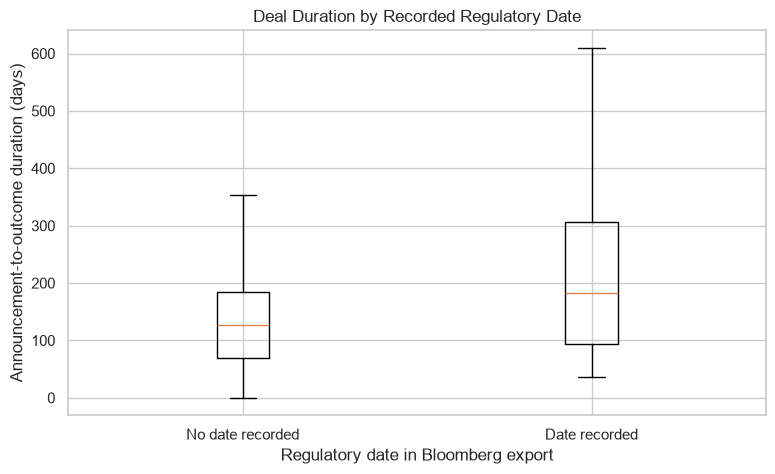

Total transactions in duration analysis: 4,755


In [11]:
# Select resolved transactions with valid, nonnegative durations.
resolved_statuses = ["Completed", "Terminated", "Withdrawn"]

duration_deals = deals[
    deals["Deal Status"].isin(resolved_statuses)
    & deals["deal_duration_days"].notna()
    & (deals["deal_duration_days"] >= 0)
].copy()

# Compare duration statistics by recorded regulatory date.
duration_summary = (
    duration_deals.groupby("regulatory_recorded")["deal_duration_days"]
    .agg(["count", "mean", "median", "std"])
    .rename(index={
        0: "No regulatory date recorded",
        1: "Regulatory date recorded"
    })
)

print("DEAL DURATION SUMMARY")
display(duration_summary.round(2))

# Visualize the difference between the two groups.
plt.figure(figsize=(9, 5))

box_groups = [
    duration_deals.loc[
        duration_deals["regulatory_recorded"] == 0,
        "deal_duration_days"
    ],
    duration_deals.loc[
        duration_deals["regulatory_recorded"] == 1,
        "deal_duration_days"
    ]
]

plt.boxplot(
    box_groups,
    showfliers=False,
    tick_labels=["No date recorded", "Date recorded"]
)

plt.title("Deal Duration by Recorded Regulatory Date")
plt.xlabel("Regulatory date in Bloomberg export")
plt.ylabel("Announcement-to-outcome duration (days)")
plt.show()

print(f"Total transactions in duration analysis: {len(duration_deals):,}")

In [12]:
# Separate transactions into two groups.
group_no_record = duration_deals.loc[
    duration_deals["regulatory_recorded"] == 0,
    "deal_duration_days"
]

group_recorded = duration_deals.loc[
    duration_deals["regulatory_recorded"] == 1,
    "deal_duration_days"
]

# Perform the Mann-Whitney U test.
u_stat, p_value = stats.mannwhitneyu(
    group_recorded,
    group_no_record,
    alternative="two-sided"
)

# Display results.
print(f"Transactions without a recorded regulatory date: {len(group_no_record):,}")
print(f"Transactions with a recorded regulatory date: {len(group_recorded):,}")
print(f"Mann-Whitney U statistic: {u_stat:,.1f}")
print("p-value: <0.001" if p_value < 0.001 else f"p-value: {p_value:.6f}")

print(f"Median duration, no date recorded: {group_no_record.median():.1f} days")
print(f"Median duration, date recorded: {group_recorded.median():.1f} days")

Transactions without a recorded regulatory date: 4,624
Transactions with a recorded regulatory date: 131
Mann-Whitney U statistic: 389,137.0
p-value: <0.001
Median duration, no date recorded: 127.0 days
Median duration, date recorded: 183.0 days


In [13]:
# Include only transactions with resolved outcomes.
outcome_data = deals[
    deals["Deal Status"].isin(resolved_statuses)
].copy()

# Create binary completion indicator.
outcome_data["completed"] = (
    outcome_data["Deal Status"] == "Completed"
).astype(int)

# Build contingency table.
outcome_table = pd.crosstab(
    outcome_data["regulatory_recorded"],
    outcome_data["completed"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

outcome_table.index = [
    "No regulatory date recorded",
    "Regulatory date recorded"
]
outcome_table.columns = [
    "Withdrawn/terminated",
    "Completed"
]

print("TRANSACTION OUTCOMES BY REGULATORY RECORD")
display(outcome_table)

# Perform Fisher's exact test.
odds_ratio, fisher_p = fisher_exact(outcome_table.values)

# Calculate completion rates.
completion_rates = (
    outcome_data.groupby("regulatory_recorded")["completed"]
    .agg(["count", "mean"])
    .rename(index={
        0: "No regulatory date recorded",
        1: "Regulatory date recorded"
    })
)

completion_rates["completion_rate_percent"] = (
    completion_rates["mean"] * 100
).round(2)

print("\nCOMPLETION RATES BY GROUP")
display(completion_rates[["count", "completion_rate_percent"]])

print(f"Fisher's exact test odds ratio: {odds_ratio:.3f}")
print(
    "Fisher exact test p-value: <0.001"
    if fisher_p < 0.001
    else f"Fisher exact test p-value: {fisher_p:.6f}"
)

TRANSACTION OUTCOMES BY REGULATORY RECORD


,Withdrawn/terminated,Completed
No regulatory date recorded,1438,3204
Regulatory date recorded,7,124



COMPLETION RATES BY GROUP


,count,completion_rate_percent
regulatory_recorded,,
No regulatory date recorded,4642,69.02
Regulatory date recorded,131,94.66


Fisher's exact test odds ratio: 7.950
Fisher exact test p-value: <0.001


In [14]:
# Prepare the regression sample.
regression_data = duration_deals[
    duration_deals["deal_value_millions"].notna()
    & (duration_deals["deal_value_millions"] > 0)
].copy()

# Log-transform duration and deal value.
regression_data["log_duration"] = np.log1p(
    regression_data["deal_duration_days"]
)

regression_data["log_deal_value"] = np.log(
    regression_data["deal_value_millions"]
)

# Consolidate rare payment categories.
payment_counts = regression_data["Payment Type"].value_counts()
common_payment_types = payment_counts[payment_counts >= 50].index

regression_data["payment_group"] = np.where(
    regression_data["Payment Type"].isin(common_payment_types),
    regression_data["Payment Type"],
    "Other"
)

# Estimate OLS regression with HC3 robust standard errors.
model = smf.ols(
    formula=(
        "log_duration ~ regulatory_recorded + log_deal_value "
        "+ C(payment_group) + announcement_year"
    ),
    data=regression_data
).fit(cov_type="HC3")

print("REGRESSION SAMPLE")
print(f"Observations: {len(regression_data):,}")
print(f"Transactions with recorded regulatory dates: "
      f"{regression_data['regulatory_recorded'].sum():,}")

print("\nREGRESSION RESULTS")
print(model.summary())

REGRESSION SAMPLE
Observations: 3,989
Transactions with recorded regulatory dates: 130

REGRESSION RESULTS
                            OLS Regression Results                            
Dep. Variable:           log_duration   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     50.32
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           5.58e-78
Time:                        19:55:55   Log-Likelihood:                -5854.8
No. Observations:                3989   AIC:                         1.173e+04
Df Residuals:                    3980   BIC:                         1.178e+04
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]


In [15]:
# Center announcement year around its sample mean
regression_data["announcement_year_centered"] = (
    regression_data["announcement_year"]
    - regression_data["announcement_year"].mean()
)

# Re-estimate the regression
model_centered = smf.ols(
    formula=(
        "log_duration ~ regulatory_recorded + log_deal_value "
        "+ C(payment_group) + announcement_year_centered"
    ),
    data=regression_data
).fit(cov_type="HC3")

print(model_centered.summary())

                            OLS Regression Results                            
Dep. Variable:           log_duration   R-squared:                       0.075
Model:                            OLS   Adj. R-squared:                  0.073
Method:                 Least Squares   F-statistic:                     50.32
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           5.58e-78
Time:                        19:57:24   Log-Likelihood:                -5854.8
No. Observations:                3989   AIC:                         1.173e+04
Df Residuals:                    3980   BIC:                         1.178e+04
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
Inte

In [16]:
coef = model_centered.params["regulatory_recorded"]
pval = model_centered.pvalues["regulatory_recorded"]

pct_difference = (np.exp(coef) - 1) * 100

print(f"Estimated regulatory-recorded coefficient: {coef:.4f}")
print(f"Adjusted duration difference: {pct_difference:.1f}%")
print("p-value: <0.001" if pval < 0.001 else f"p-value: {pval:.6f}")

if pval < 0.05:
    print("The model estimates a statistically significant association at the 5% level.")
else:
    print("The model does not estimate a statistically significant association at the 5% level.")

print("Interpret this as an adjusted association, not a causal effect.")

Estimated regulatory-recorded coefficient: 0.3536
Adjusted duration difference: 42.4%
p-value: <0.001
The model estimates a statistically significant association at the 5% level.
Interpret this as an adjusted association, not a causal effect.


In [17]:
value_cutoff = regression_data["deal_value_millions"].quantile(0.99)

robust_data = regression_data[
    regression_data["deal_value_millions"] <= value_cutoff
].copy()

robust_model = smf.ols(
    formula=(
        "log_duration ~ regulatory_recorded + log_deal_value "
        "+ C(payment_group) + announcement_year_centered"
    ),
    data=robust_data
).fit(cov_type="HC3")

comparison = pd.DataFrame({
    "Full sample": [
        model_centered.params["regulatory_recorded"],
        model_centered.pvalues["regulatory_recorded"],
        len(regression_data)
    ],
    "Excluding top 1% by deal value": [
        robust_model.params["regulatory_recorded"],
        robust_model.pvalues["regulatory_recorded"],
        len(robust_data)
    ]
}, index=["Regulatory coefficient", "p-value", "Observations"])

display(comparison.round(4))

,Full sample,Excluding top 1% by deal value
Regulatory coefficient,0.3536,0.3132
p-value,0.0000,0.0000
Observations,3989.0000,3949.0000


In [18]:
conf_int = model_centered.conf_int().loc["regulatory_recorded"]

lower_pct = (np.exp(conf_int.iloc[0]) - 1) * 100
upper_pct = (np.exp(conf_int.iloc[1]) - 1) * 100

print("MAIN REGRESSION")
print(f"Adjusted duration difference: {pct_difference:.1f}%")
print(f"95% confidence interval: {lower_pct:.1f}% to {upper_pct:.1f}%")
print(f"p-value: {pval:.4g}")

MAIN REGRESSION
Adjusted duration difference: 42.4%
95% confidence interval: 25.0% to 62.2%
p-value: 1.018e-07


In [20]:
ear_model = smf.ols(
    formula=(
        "log_duration ~ regulatory_recorded + log_deal_value "
        "+ C(payment_group) + C(announcement_year)"
    ),
    data=regression_data
).fit(cov_type="HC3")

print("CATEGORICAL-YEAR REGRESSION")
print("Regulatory coefficient:",
      round(year_model.params["regulatory_recorded"], 4))
print("P-value:",
      year_model.pvalues["regulatory_recorded"])
print(year_model.summary())

CATEGORICAL-YEAR REGRESSION
Regulatory coefficient: 0.3489
P-value: 2.0548302784628174e-07
                            OLS Regression Results                            
Dep. Variable:           log_duration   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.076
Method:                 Least Squares   F-statistic:                     25.87
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           5.44e-74
Time:                        20:02:57   Log-Likelihood:                -5843.0
No. Observations:                3989   AIC:                         1.172e+04
Df Residuals:                    3972   BIC:                         1.183e+04
Df Model:                          16                                         
Covariance Type:                  HC3                                         
                                         coef    std err          z      P>|z|      [0.025      0.975]
----------------

In [21]:
export_columns = [
    "Action ID", "Announce Date", "Target Name", "Acquirer Name",
    "Announced Total Value (mil.)", "Payment Type", "Deal Status",
    "Completion/Termination Date", "Anti-Trust Commission",
    "FIC: Foreign Investment Committee", "regulatory_recorded",
    "deal_duration_days", "announcement_year"
]

clean_export = deals[export_columns].copy()
clean_export.to_csv("cleaned_ma_analysis.csv", index=False)

print("Saved cleaned_ma_analysis.csv")

Saved cleaned_ma_analysis.csv
